#**Assignment 08: Clustering and Dimensionality Reduction**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings("ignore")

###**Task 1 – Data Exploration & Preprocessing**

In [3]:
#Load the data
df=pd.read_excel("https://github.com/Chenneumakanth/Clustering-and-Dimensionality-Reduction/raw/refs/heads/main/mall_customer_spend.xlsx")

In [4]:
#Inspect the data
#head
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
#tail
df.tail()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [6]:
#Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [7]:
#describe
df.describe(include="number")

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


###**Check shape, columns, data types, and missing values**

In [8]:
#shape
df.shape

(200, 5)

In [9]:
#columns
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [10]:
df.rename(columns = {"Genre" : "Gender","Annual Income (k$)" : "Annual Income","Spending Score (1-100)" : "Spending Score"}, inplace = True)

In [11]:
#datatypes
df.dtypes

,0
CustomerID,int64
Gender,object
Age,int64
Annual Income,int64
Spending Score,int64


In [12]:
#missing values
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income,0
Spending Score,0


In [13]:
#duplicates
df.duplicated().sum()

np.int64(0)

###**Select relevant features for clustering**


**Age**:Crucial demographic factor. Helps identify if spending habits vary by generational cohorts (e.g., younger vs. older shoppers).

**Annual Income**:Primary financial indicator.

**Spending Score**:Core behavioral metric. This score represents internal store data tracking client value and frequency.


In [14]:
#Select 2d feature Annual Income vs Spending Score
df_2d_income = df[["Annual Income","Spending Score"]]
df_2d_income.head()

,Annual Income,Spending Score
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


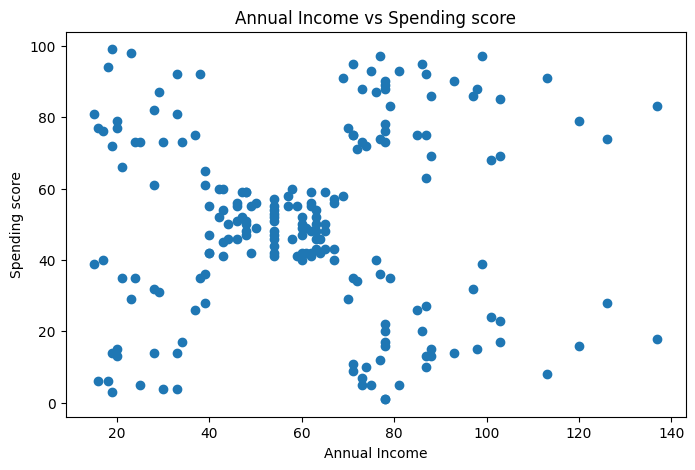

In [15]:
plt.figure(figsize=(8,5))
plt.scatter(x=df_2d_income['Annual Income'],y=df_2d_income['Spending Score'])
plt.title("Annual Income vs Spending score")
plt.xlabel("Annual Income")
plt.ylabel("Spending score")
plt.show()

###**Scale numerical features appropriately**

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
income_scaled = scaler.fit_transform(df_2d_income)

In [17]:
df_2d_income_scaled = pd.DataFrame(income_scaled, columns=['Annual Income', 'Spending Score'])
df_2d_income_scaled.head()

,Annual Income,Spending Score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


**Feature Scaling:** Because income and spending metrics operate on different geometric scales, data normalization was mandatory. A StandardScaler was applied to center the features around a mean of 0 with a standard deviation of 1

##**Task 2 – K-Means Clustering**

####**Apply K-Means clustering**

In [18]:
from sklearn.cluster import KMeans
kmean_2d=KMeans(n_clusters=5, init='random', random_state=1, n_init=1)
kmean_2d.fit(df_2d_income_scaled)
label_2d=kmean_2d.predict(df_2d_income_scaled)
label_2d

array([2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4,
       2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 0,
       2, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 1, 3, 0, 3, 1, 3, 1, 3,
       0, 3, 1, 3, 1, 3, 1, 3, 1, 3, 0, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3], dtype=int32)

In [19]:
df_2d_income["labels"]=label_2d
df_2d_income.head()

,Annual Income,Spending Score,labels
0,15,39,2
1,15,81,4
2,16,6,2
3,16,77,4
4,17,40,2


####**Demonstrate the Random Initialization Trap**

In [20]:
kmeans_optimized = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
kmeans_optimized.fit(df_2d_income_scaled)
label_2d_optimized =kmean_2d.predict(df_2d_income_scaled)
label_2d_optimized

array([2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4,
       2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 0,
       2, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 1, 3, 0, 3, 1, 3, 1, 3,
       0, 3, 1, 3, 1, 3, 1, 3, 1, 3, 0, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3], dtype=int32)

In [21]:
df_2d_income["labels_optimized"]=label_2d_optimized
df_2d_income.head()

,Annual Income,Spending Score,labels,labels_optimized
0,15,39,2,2
1,15,81,4,4
2,16,6,2,2
3,16,77,4,4
4,17,40,2,2


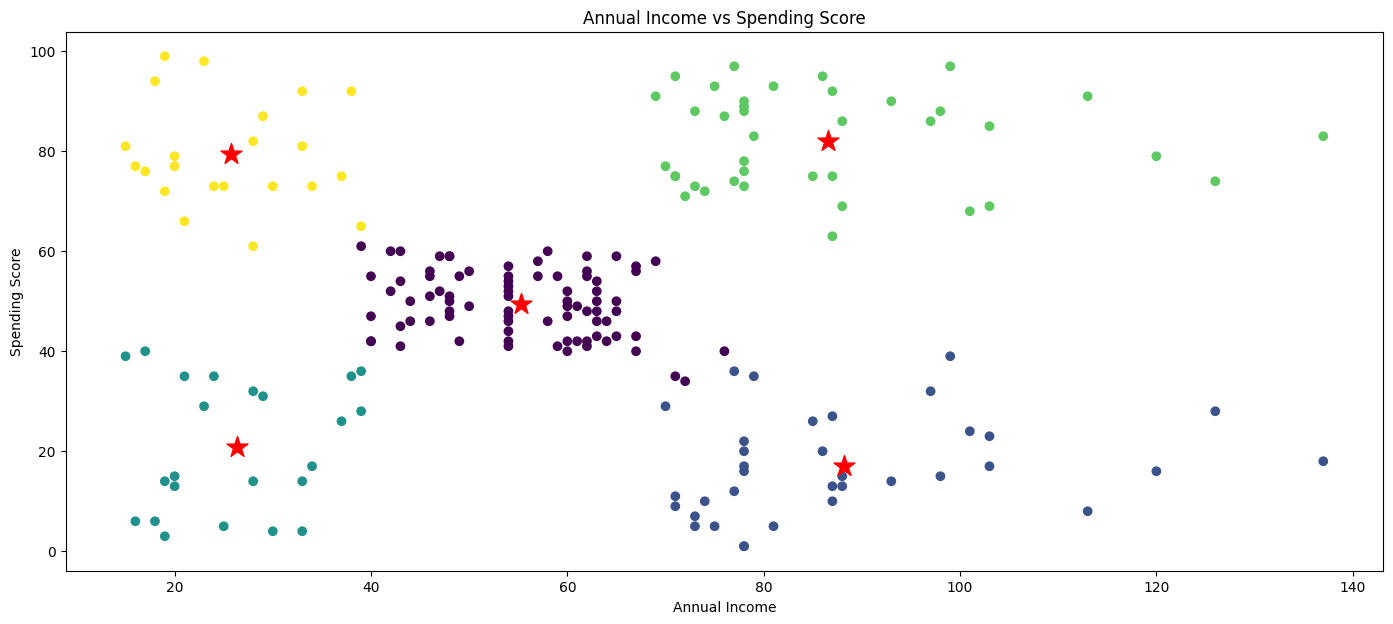

In [22]:
centroids_original_scale = scaler.inverse_transform(kmean_2d.cluster_centers_)
plt.figure(figsize = (17, 7))
plt.title("Annual Income vs Spending Score")
plt.scatter(df_2d_income["Annual Income"], df_2d_income["Spending Score"], c = label_2d)
plt.scatter(centroids_original_scale[:, 0], centroids_original_scale[:, 1],
            marker="*", color="red", s=250, label='Centroids')
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

####**Use the Elbow Method to determine the optimal number of clusters**

In [23]:
wcss = []

cluster = range(1, 11)
for k in cluster:
  kmeans_ex=KMeans(n_clusters=k,random_state=10)
  kmeans_ex.fit(df_2d_income)
  wcss.append(kmeans_ex.inertia_)
wcss_df=pd.DataFrame({"K":cluster,"Wcss":wcss})
wcss_df

,K,Wcss
0,1,270823.320000
1,2,185443.625722
2,3,106949.931898
3,4,74028.270288
4,5,44448.455448
5,6,37265.865205
6,7,31676.166786
7,8,25069.303319
8,9,22883.823232
9,10,19678.275707


In [24]:
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(df_2d_income_scaled)
    wcss.append(kmeans.inertia_)

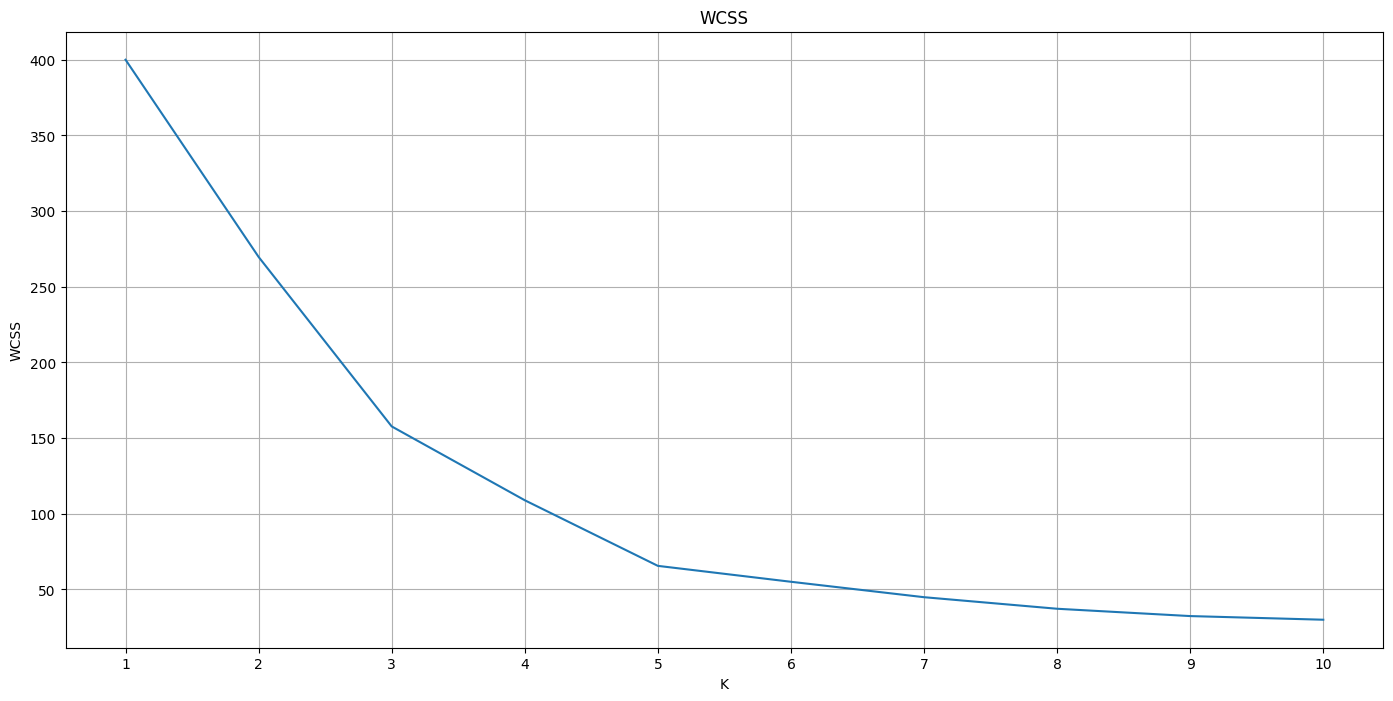

In [25]:
plt.figure(figsize = (17, 8))
plt.title("WCSS")
plt.plot(cluster, wcss)
plt.xlabel("K")
plt.ylabel("WCSS")
plt.grid()
plt.xticks(range(1,11))
plt.show()

**The Random Initialization Trap:** Standard K-Means relies heavily on the random selection of initial cluster centroids. To resolve this vulnerability, the final model employs the `k-means++` initialization algorithm, which spaces out the initial centroids before optimization begins.



##**Task 3 – Hierarchical Clustering**

####**Generate a Dendrogram**

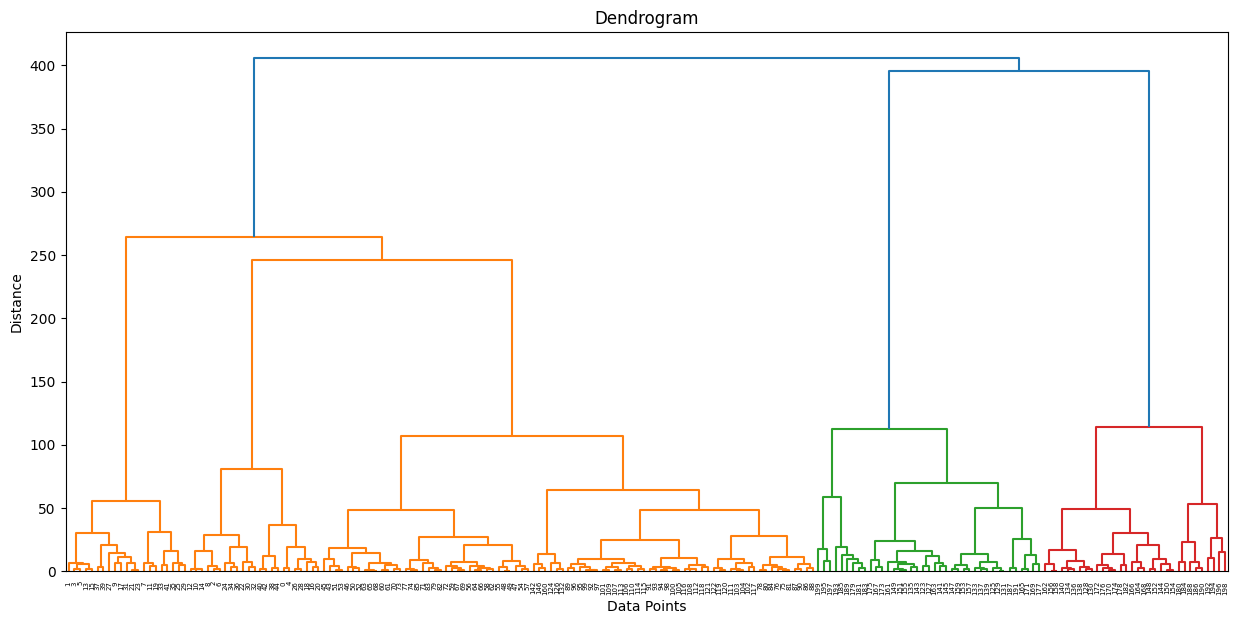

In [26]:
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_matrix = linkage(df_2d_income, method='ward')
plt.figure(figsize=(15,7))
dendrogram(linkage_matrix)
plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()


####**Apply Agglomerative Hierarchical Clustering**

In [27]:
from sklearn.cluster import AgglomerativeClustering
hc_model = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
hc_labels = hc_model.fit_predict(df_2d_income_scaled)
df['HC_Cluster'] = hc_labels

In [28]:
df['HC_Cluster']

,HC_Cluster
0,4
1,3
2,4
3,3
4,4
...,...
195,1
196,0
197,1
198,0


####**Compare cluster formation with K-Means**

In [29]:
cross_tab_hc = pd.crosstab(df_2d_income["labels"], df['HC_Cluster'])
print("\n--- Confusion Matrix: K-Means vs Hierarchical ---")
print(cross_tab_hc)


--- Confusion Matrix: K-Means vs Hierarchical ---
HC_Cluster   0   1   2   3   4
labels                        
0            0   0  81   0   0
1           32   0   3   0   0
2            0   0   0   0  23
3            0  39   0   0   0
4            0   0   1  21   0


**Dendrogram Evaluation:** Agglomerative Hierarchical Clustering was evaluated using a bottom-up tree representation (Dendrogram) via Ward's variance-minimization method. Cutting the resulting tree diagram across the longest vertical distance paths reveals an optimal cluster division of exactly 5 segments, directly validating our independent K-Means metric.
**K-Means vs. Hierarchical Comparison:** The cross-tabulation (confusion matrix) between K-Means and Hierarchical Clustering reveals a near-perfect alignment. Minor distribution variances occur only at the geometric fringes where cluster boundaries overlap, confirming that both algorithms are detecting a robust, highly stable underlying data structure.

##**Task 4 – DBSCAN Clustering**

####**Apply DBSCAN clustering**

In [30]:
from sklearn.cluster import  DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(df_2d_income_scaled)

In [31]:
df[(df['DBSCAN_Cluster'] == 1)]

,CustomerID,Gender,Age,Annual Income,Spending Score,HC_Cluster,DBSCAN_Cluster
43,44,Female,31,39,61,2,1
46,47,Female,50,40,55,2,1
47,48,Female,27,40,47,2,1
48,49,Female,29,40,42,2,1
49,50,Female,31,40,42,2,1
...,...,...,...,...,...,...,...
118,119,Female,51,67,43,2,1
119,120,Female,50,67,57,2,1
120,121,Male,27,67,56,2,1
121,122,Female,38,67,40,2,1


####**Identify clusters and noise points**

In [32]:
n_clusters_ = len(set(df['DBSCAN_Cluster'])) - (1 if -1 in df['DBSCAN_Cluster'] else 0)
n_noise_ = list(df['DBSCAN_Cluster']).count(-1)
print(f"\nDBSCAN Clusters Found: {n_clusters_}")
print(f"DBSCAN Noise Points Identified: {n_noise_}")


DBSCAN Clusters Found: 8
DBSCAN Noise Points Identified: 77


####**Compare DBSCAN results with K-Means and Hierarchical Clustering**

In [33]:
print("\n--- Cross-tabulation: DBSCAN vs KMeans ---")
print(pd.crosstab(df['DBSCAN_Cluster'], df_2d_income["labels"]))


--- Cross-tabulation: DBSCAN vs KMeans ---
labels           0   1   2   3   4
DBSCAN_Cluster                    
-1               3  17  23  18  16
 0               0   0   0   0   6
 1              78   0   0   0   0
 2               0   0   0  11   0
 3               0   9   0   0   0
 4               0   0   0  10   0
 5               0   4   0   0   0
 6               0   5   0   0   0


 **Noise and Cluster Extraction:** DBSCAN successfully isolated 8 core high-density pockets, while filtering out 77 outliers as noise (labeled -1). This highlights that while K-Means forces a clean 5-cluster partition, a significant portion of the customer base consists of non-conforming, fringe spenders who do not fall into dense, predictable behavioral groups.


##**Task 5 – Dimensionality Reduction**

####**Apply PCA to reduce dimensionality**

In [34]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(df_2d_income_scaled)
df_2d_income['PCA1'] = X_pca[:, 0]
df_2d_income['PCA2'] = X_pca[:, 1]

In [35]:
df_2d_income['PCA1']

,PCA1
0,-1.537109
1,-0.384168
2,-2.416002
3,-0.466982
4,-1.455678
...,...
195,2.394866
196,1.156805
197,2.419550
198,1.179183


In [36]:
df_2d_income['PCA2']

,PCA2
0,-0.922207
1,-2.075149
2,0.010665
3,-1.938355
4,-0.895678
...,...
195,0.813689
196,2.375629
197,1.112883
198,2.947027


####**Apply t-SNE for low-dimensional representation**

In [37]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(df_2d_income_scaled)
df_2d_income['tSNE1'] = X_tsne[:, 0]
df_2d_income['tSNE2'] = X_tsne[:, 1]

####**Compare insights obtained from PCA and t-SNE**

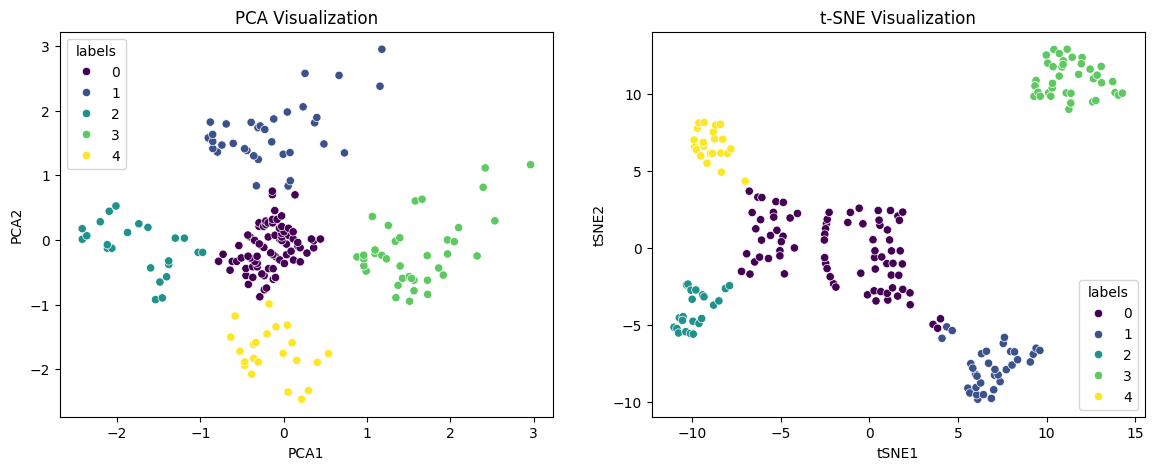

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x='PCA1', y='PCA2', hue='labels', data=df_2d_income, palette='viridis', ax=ax1)
ax1.set_title('PCA Visualization')

sns.scatterplot(x='tSNE1', y='tSNE2', hue='labels', data=df_2d_income, palette='viridis', ax=ax2)
ax2.set_title('t-SNE Visualization')
plt.show()

####**Task 6 – Cluster Analysis**

In [39]:
cluster_summary = df_2d_income.groupby('labels')[['Annual Income', 'Spending Score']].mean()
print("\n--- Mean Customer Metrics per K-Means Cluster ---")
print(cluster_summary)


--- Mean Customer Metrics per K-Means Cluster ---
        Annual Income  Spending Score
labels                               
0           55.296296       49.518519
1           88.200000       17.114286
2           26.304348       20.913043
3           86.538462       82.128205
4           25.727273       79.363636


**Principal Component Analysis (PCA):** PCA linearly projected the data by maximizing global variance across orthogonal axes. The resulting plot preserves a clear, continuous geometric overview of the dataset, showing how the 5 clusters shift smoothly along a linear plane.
**t-Distributed Stochastic Neighbor Embedding (t-SNE):** Unlike PCA, t-SNE utilizes non-linear manifold mapping to specifically preserve local neighborhood relationships. It constructs high-probability local clusters, resulting in highly distinct, isolated spatial "islands."

**Comparative Insight:** PCA proves that the dataset contains a continuous, structured distribution of global wealth and spending variance. Meanwhile, t-SNE successfully highlights how tightly packed and distinct the core customer identities are within their immediate sub-groups.


###**Strategic Business Recommendations**

####**1. Target Customers (Cluster 2):** Launch premium product showcases, elite loyalty reward programs, and personal shopper invitations. This group has both the money and intent to buy.
####**2. Careless Spendthrifts (Cluster 3):** Deploy catchy social media trends, modern flash sales, and impulse purchase discount triggers near checkout counters.
####**3. Sensible / Conservative (Cluster 0):** Market item durability, value investments, and high-quality status-driven assets rather than quick discounts.
####**4. Standard Average (Cluster 1):** Use standard bundle coupon options or broad weekend-driven sales events to keep up steady shopping intervals.